1.using linear regression

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load dataset
df = pd.read_csv('netflix_revenue_updated.csv')

# 2. Prepare features and target
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df['Year'] = df['Date'].dt.year
df['Quarter'] = df['Date'].dt.quarter

X = df.drop(['Global Revenue', 'Date'], axis=1)
y = df['Global Revenue']

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Fit Linear Regression
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

# 6. Prediction and Evaluation
y_pred = lr.predict(X_test_scaled)

print("R2 Score:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

# 7. Feature Coefficients
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr.coef_
}).sort_values(by='Coefficient', ascending=False)

print("\nLinear Regression Coefficients:")
print(coefficients)

R2 Score: 0.9936608183133551
RMSE: 120820082.62048629

Linear Regression Coefficients:
                           Feature   Coefficient
2           LATM Streaming Revenue  9.042844e+08
5                    EMEA  Members  7.197964e+08
8                        UCAN ARPU  5.599779e+08
4                     UCAN Members  2.808302e+08
1           EMEA Streaming Revenue  2.619638e+08
3           APAC Streaming Revenue  8.312358e+07
9                        EMEA ARPU  4.466020e+07
12  Netflix Streaming Memberships   4.046418e+07
11                      APAC  ARPU  1.677284e+07
14                         Quarter -2.184655e+07
13                            Year -2.984151e+07
0           UCAN Streaming Revenue -4.002322e+07
10                      LATM  ARPU -3.083625e+08
7                     APAC Members -3.717321e+08
6                     LATM Members -1.027997e+09


2. using KNN (K-Nearest Neighbors)

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load dataset
df = pd.read_csv('netflix_revenue_updated.csv')

# 2. Prepare features and target
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df['Year'] = df['Date'].dt.year
df['Quarter'] = df['Date'].dt.quarter

X = df.drop(['Global Revenue', 'Date'], axis=1)
y = df['Global Revenue']

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Hyperparameter Tuning
cv = KFold(n_splits=3, shuffle=True, random_state=42)

param_grid = {
    'n_neighbors': range(1, 11),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

knn_grid = GridSearchCV(
    KNeighborsRegressor(), param_grid, cv=cv, scoring='r2'
)

knn_grid.fit(X_train_scaled, y_train)

# 6. Best Model Evaluation
best_knn = knn_grid.best_estimator_
y_pred = best_knn.predict(X_test_scaled)

print("Best Parameters:", knn_grid.best_params_)
print("R2 Score:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)

Best Parameters: {'metric': 'manhattan', 'n_neighbors': 2, 'weights': 'distance'}
R2 Score: 0.9189095730452185
RMSE: 432122940.09248304


3. Decision Tree

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load dataset
df = pd.read_csv('netflix_revenue_updated.csv')

# 2. Prepare features and target
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df['Year'] = df['Date'].dt.year
df['Quarter'] = df['Date'].dt.quarter

X = df.drop(['Global Revenue', 'Date'], axis=1)
y = df['Global Revenue']

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Hyperparameter Tuning
cv = KFold(n_splits=3, shuffle=True, random_state=42)

param_grid = {
    'max_depth': [2, 3, 4, 5, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

dt_grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid, cv=cv, scoring='r2'
)

dt_grid.fit(X_train, y_train)

# 5. Evaluate Best Decision Tree
best_dt = dt_grid.best_estimator_
y_pred = best_dt.predict(X_test)

print("Best Parameters:", dt_grid.best_params_)
print("R2 Score:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)

# 6. Feature Importances
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_dt.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nFeature Importances:")
print(importances)

Best Parameters: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
R2 Score: 0.9074602026719688
RMSE: 461622321.54441535

Feature Importances:
                           Feature  Importance
13                            Year    0.783715
2           LATM Streaming Revenue    0.120179
4                     UCAN Members    0.060936
0           UCAN Streaming Revenue    0.030625
3           APAC Streaming Revenue    0.004545
5                    EMEA  Members    0.000000
1           EMEA Streaming Revenue    0.000000
6                     LATM Members    0.000000
7                     APAC Members    0.000000
9                        EMEA ARPU    0.000000
8                        UCAN ARPU    0.000000
10                      LATM  ARPU    0.000000
11                      APAC  ARPU    0.000000
12  Netflix Streaming Memberships     0.000000
14                         Quarter    0.000000


4. Random Forest

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Load dataset
df = pd.read_csv('netflix_revenue_updated.csv')

# 2. Prepare features and target
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df['Year'] = df['Date'].dt.year
df['Quarter'] = df['Date'].dt.quarter

X = df.drop(['Global Revenue', 'Date'], axis=1)
y = df['Global Revenue']

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Hyperparameter Tuning
cv = KFold(n_splits=3, shuffle=True, random_state=42)

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid, cv=cv, scoring='r2'
)

rf_grid.fit(X_train, y_train)

# 5. Evaluate Best Random Forest
best_rf = rf_grid.best_estimator_
y_pred = best_rf.predict(X_test)

print("Best Parameters:", rf_grid.best_params_)
print("R2 Score:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)

# 6. Feature Importances
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nFeature Importances:")
print(importances)

Best Parameters: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
R2 Score: 0.8983166077240174
RMSE: 483890996.996337

Feature Importances:
                           Feature  Importance
2           LATM Streaming Revenue    0.109433
1           EMEA Streaming Revenue    0.108546
0           UCAN Streaming Revenue    0.099041
7                     APAC Members    0.097854
3           APAC Streaming Revenue    0.096113
12  Netflix Streaming Memberships     0.093537
8                        UCAN ARPU    0.091661
5                    EMEA  Members    0.082199
6                     LATM Members    0.071812
13                            Year    0.060515
4                     UCAN Members    0.045898
9                        EMEA ARPU    0.017431
11                      APAC  ARPU    0.015815
10                      LATM  ARPU    0.007887
14                         Quarter    0.002257


5. Hierarchical Clustering

Hierarchical Clustering Results
Silhouette Score: 0.3885526352558286

Cluster Results:
    Global Revenue  Cluster
0       4520992000        0
1       4923116000        0
2       5244905000        0
3       5467434000        0
4       5767691000        0
5       6148286000        0
6       6435637000        0
7       6644442000        0
8       7163282000        0
9       7341777000        0
10      7483467000        0
11      7709318000        0
12      7867767000        0
13      7970141000        1
14      7925589000        1
15      7852053000        1
16      8161503000        1
17      8187301000        1
18      8541668000        1
19      8832825000        1
20      9370440000        1


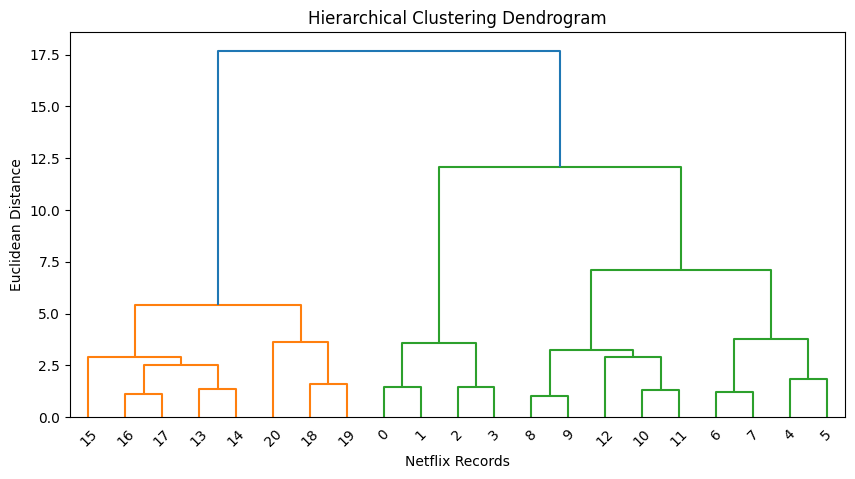

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# 1. Load dataset
df = pd.read_csv('netflix_revenue_updated.csv')

# 2. Prepare features
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df['Year'] = df['Date'].dt.year
df['Quarter'] = df['Date'].dt.quarter

X = df.drop(['Global Revenue', 'Date'], axis=1)

# 3. Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Hierarchical Clustering
agg = AgglomerativeClustering(
    n_clusters=2, linkage='ward'
)

cluster_labels = agg.fit_predict(X_scaled)

# 5. Evaluate Clustering
sil = silhouette_score(X_scaled, cluster_labels)

print("Hierarchical Clustering Results")
print("Silhouette Score:", sil)

df['Cluster'] = cluster_labels
print("\nCluster Results:")
print(df[['Global Revenue', 'Cluster']])

# 6. Plot Dendrogram
plt.figure(figsize=(10, 5))
plt.title("Hierarchical Clustering Dendrogram")
sch.dendrogram(sch.linkage(X_scaled, method='ward'))
plt.xlabel("Netflix Records")
plt.ylabel("Euclidean Distance")
plt.show()

6. K-Means Clustering

In [7]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Load dataset
df = pd.read_csv('netflix_revenue_updated.csv')

# 2. Prepare features
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df['Year'] = df['Date'].dt.year
df['Quarter'] = df['Date'].dt.quarter

X = df.drop(['Global Revenue', 'Date'], axis=1)

# 3. Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Fit K-Means Clustering
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

cluster_labels = kmeans.fit_predict(X_scaled)

# 5. Evaluate Clustering
sil = silhouette_score(X_scaled, cluster_labels)

print("K-Means Clustering Results")
print("Silhouette Score:", sil)

# 6. View Cluster Centers
centers = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=X.columns
)

print("\nCluster Centers:")
print(centers)

# 7. Display Cluster Results
df['Cluster'] = cluster_labels
print("\nNetflix Revenue Clusters:")
print(df[['Global Revenue', 'Cluster']])

K-Means Clustering Results
Silhouette Score: 0.4468114619898114

Cluster Centers:
   UCAN Streaming Revenue  EMEA Streaming Revenue  LATM Streaming Revenue  \
0            3.524544e+09            2.535344e+09            1.019878e+09   
1            2.688326e+09            1.664415e+09            7.440201e+08   

   APAC Streaming Revenue  UCAN Members  EMEA  Members  LATM Members  \
0            8.941133e+08  7.563038e+07   7.693723e+07  4.134208e+07   
1            4.802276e+08  6.972500e+07   5.438262e+07  3.256012e+07   

   APAC Members  UCAN ARPU  EMEA ARPU  LATM  ARPU  APAC  ARPU  \
0  3.657415e+07  15.701538  11.145385    8.286923    8.488462   
1  1.839050e+07  12.940000  10.512500    7.833750    9.180000   

   Netflix Streaming Memberships          Year   Quarter  
0                    2.304838e+08  2022.153846  2.384615  
1                    1.750582e+08  2019.500000  2.500000  

Netflix Revenue Clusters:
    Global Revenue  Cluster
0       4520992000        1
1       49231

**Final Analysis**


The performance of all four supervised machine learning algorithms was compared using Mean Absolute Error (MAE) and R² Score. Linear Regression performed best with an R² score of 99.67% and the lowest MAE of 86.26M. This shows that Linear Regression gives the best prediction results among the supervised algorithms used.



KNN, Decision Tree, and Random Forest also showed good performance, but their prediction errors were higher than Linear Regression. Hierarchical Clustering and K-Means were used to group similar revenue records. Since these are unsupervised algorithms, they are evaluated using the Silhouette Score instead of MAE and R² Score